# Chapter 2: Multi-Armed Bandits

A hands-on notebook for learning the main action-selection ideas from **Sutton & Barto, Reinforcement Learning: An Introduction, Chapter 2**.

This notebook covers:

1. **Greedy action selection**
2. **$\epsilon$-greedy action selection**
3. **Optimistic initial values**
4. **Upper Confidence Bound (UCB) action selection**
5. The **exploration vs. exploitation** tradeoff
6. A fair experimental comparison of all four methods

The core bandit problem is simple:

> At each step, choose one action from several possibilities. Each action has an unknown expected reward. Learn which action is best while trying to collect as much reward as possible.

That simple setup is enough to expose one of reinforcement learning's central problems:

\[
\boxed{\text{Should I exploit what I know, or explore what I do not know?}}
\]


Estimated pi: 3.112
True pi: 3.141592653589793


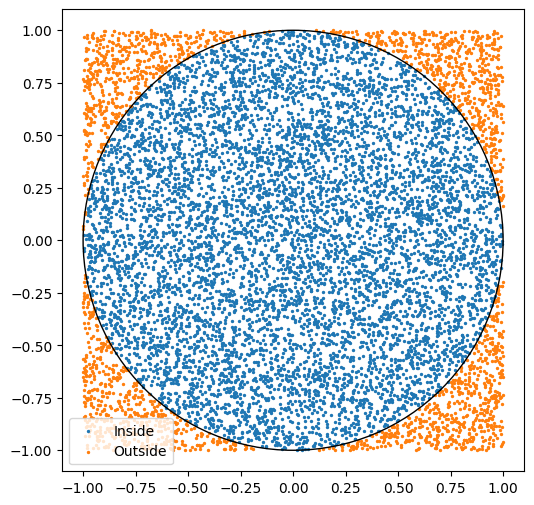

In [30]:
import numpy as np
import matplotlib.pyplot as plt

N = 10_000
rnd_seed = np.random.randint(0, 10000)

rng = np.random.default_rng(rnd_seed)

# Generate random points
x = rng.uniform(-1, 1, N)
y = rng.uniform(-1, 1, N)

# Identify points inside the circle
inside = x**2 + y**2 <= 1

# Estimate pi
pi_estimate = 4 * np.mean(inside)

print("Estimated pi:", pi_estimate)
print("True pi:", np.pi)

# Visualization
fig, ax = plt.subplots(figsize=(6, 6))

ax.scatter(x[inside], y[inside],
           s=2, label="Inside")

ax.scatter(x[~inside], y[~inside],
           s=2, label="Outside")

circle = plt.Circle((0, 0), 1, fill=False)

ax.add_patch(circle)
ax.set_aspect("equal")
ax.legend()

plt.show()

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)


## 1. The k-armed bandit problem

Suppose we have $k$ possible actions.

Each action $a$ has an unknown true value

\[
q_*(a) = \mathbb{E}[R_t \mid A_t=a].
\]

The agent does not know $q_*(a)$.

Instead, it maintains an estimate

\[
Q_t(a).
\]

A common estimator is the sample average:

\[
Q_t(a)
=
\frac{\text{sum of rewards from action }a}
{\text{number of times action }a\text{ was selected}}.
\]

Incrementally:

\[
Q(a)
\leftarrow
Q(a)
+
\frac{1}{N(a)}
\left[R-Q(a)\right].
\]


The update has the generic form

\[
\text{new estimate}
=
\text{old estimate}
+
\text{step size}
\times
\text{error}.
\]

For sample averages:

\[
\text{step size} = \frac{1}{N(a)}
\]

and

\[
\text{error} = R-Q(a).
\]

This pattern will appear again and again in reinforcement learning. Apparently one equation was not enough, so the field built a career out of variations of it.


In [2]:
class KArmedBandit:
    def __init__(self, k=10, reward_std=1.0, seed=None):
        self.k = k
        self.reward_std = reward_std
        self.rng = np.random.default_rng(seed)

        # Hidden true action values
        self.true_values = self.rng.normal(0.0, 1.0, size=k)

    @property
    def optimal_action(self):
        return int(np.argmax(self.true_values))

    def step(self, action):
        return self.rng.normal(
            loc=self.true_values[action],
            scale=self.reward_std
        )


In [3]:
bandit = KArmedBandit(k=10, seed=7)

print("True action values:")
for i, q in enumerate(bandit.true_values):
    print(f"Action {i}: q*(a) = {q:.3f}")

print("\nOptimal action:", bandit.optimal_action)


True action values:
Action 0: q*(a) = 0.001
Action 1: q*(a) = 0.299
Action 2: q*(a) = -0.274
Action 3: q*(a) = -0.891
Action 4: q*(a) = -0.455
Action 5: q*(a) = -0.992
Action 6: q*(a) = 0.060
Action 7: q*(a) = 1.340
Action 8: q*(a) = -0.492
Action 9: q*(a) = -0.620

Optimal action: 7


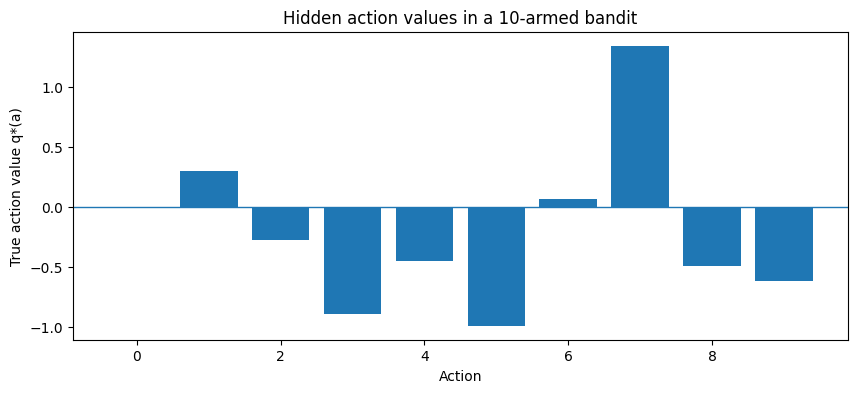

In [4]:
plt.figure(figsize=(10, 4))
plt.bar(np.arange(bandit.k), bandit.true_values)
plt.axhline(0, linewidth=1)
plt.xlabel("Action")
plt.ylabel("True action value q*(a)")
plt.title("Hidden action values in a 10-armed bandit")
plt.show()


The agent never gets to see the true values above.

It only observes rewards after taking actions.

That distinction is what makes this a learning problem rather than a glorified lookup table.


# 2. Greedy action selection

The greedy method always chooses the action with the largest current estimate:

\[
A_t = \arg\max_a Q_t(a).
\]

This is pure **exploitation**.

The agent acts entirely according to what it currently believes.


In [5]:
def greedy_action(Q, rng):
    max_value = np.max(Q)
    candidates = np.flatnonzero(Q == max_value)
    return int(rng.choice(candidates))


Q = np.array([0.5, 1.2, 0.9, 1.0])
rng = np.random.default_rng(0)

print("Q =", Q)
print("Greedy action =", greedy_action(Q, rng))


Q = [0.5 1.2 0.9 1. ]
Greedy action = 1


## Why greedy can fail

Suppose:

\[
q_*(A)=1.0,\qquad q_*(B)=1.5.
\]

So B is truly better.

But due to reward noise, suppose the first observed rewards are:

\[
R(A)=2.0,\qquad R(B)=0.2.
\]

Then the estimates become:

\[
Q(A)=2.0,\qquad Q(B)=0.2.
\]

A greedy agent prefers A.

If it never tries B again, it may never discover that B is actually better.

This is the exploration problem in its simplest form.


# 3. $\epsilon$-greedy action selection

The $\epsilon$-greedy method deliberately introduces exploration.

With probability $1-\epsilon$:

\[
A_t=\arg\max_a Q_t(a)
\]

and with probability $\epsilon$:

\[
A_t=\text{random action}.
\]

So:

- small $\epsilon$ means mostly exploitation,
- large $\epsilon$ means more exploration.


In [6]:
def epsilon_greedy_action(Q, epsilon, rng):
    if rng.random() < epsilon:
        return int(rng.integers(len(Q)))

    return greedy_action(Q, rng)


In [7]:
Q = np.array([0.5, 1.2, 0.9, 1.0])

for epsilon in [0.0, 0.1, 0.5, 1.0]:
    rng = np.random.default_rng(10)

    actions = [
        epsilon_greedy_action(Q, epsilon, rng)
        for _ in range(20)
    ]

    print(f"epsilon={epsilon}: {actions}")


epsilon=0.0: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
epsilon=0.1: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
epsilon=0.5: [1, 3, 3, 1, 1, 1, 2, 1, 1, 2, 1, 1, 1, 2, 1, 1, 3, 1, 0, 1]
epsilon=1.0: [1, 0, 3, 2, 1, 3, 0, 3, 3, 3, 3, 0, 1, 3, 2, 1, 2, 1, 0, 1]


For $k$ actions, the greedy action is selected with probability

\[
1-\epsilon+\frac{\epsilon}{k}.
\]

Why not simply $1-\epsilon$?

Because during random exploration, the greedy action can still be selected by chance.


# 4. Optimistic initial values

Instead of initializing

\[
Q_1(a)=0,
\]

we deliberately start with estimates that are too large, for example:

\[
Q_1(a)=5.
\]

The idea is:

> Untried actions still look extremely attractive.

As soon as an action is sampled, its estimate starts falling toward reality.

That causes a greedy agent to move toward other still-optimistic actions.


Suppose three actions have true values

\[
q_*(A)=1.0,\qquad
q_*(B)=1.5,\qquad
q_*(C)=2.0.
\]

But initialize all estimates as

\[
Q(A)=Q(B)=Q(C)=5.
\]

If A is tried first and gives reward 1.2:

\[
Q(A)=1.2.
\]

Now:

\[
Q(A)=1.2,\quad
Q(B)=5,\quad
Q(C)=5.
\]

So greedy action selection naturally moves toward B or C.

Optimism therefore creates **temporary exploration pressure** without using $\epsilon>0$.


Important limitation:

Optimistic initialization mainly encourages **early exploration**.

Once all action estimates have been corrected downward, the optimism disappears.

So it is much less suitable for problems where action values change over time.


# 5. Upper Confidence Bound (UCB)

UCB explores in a more targeted way than $\epsilon$-greedy.

Instead of randomly exploring, it prefers actions that either:

1. have a high estimated reward, or
2. have not been sampled much.

The classic UCB action-selection rule is:

\[
A_t
=
\arg\max_a
\left[
Q_t(a)
+
c\sqrt{\frac{\ln t}{N_t(a)}}
\right].
\]

There are two terms:

\[
\underbrace{Q_t(a)}_{\text{exploitation}}
+
\underbrace{c\sqrt{\frac{\ln t}{N_t(a)}}}_{\text{exploration bonus}}.
\]


Interpretation:

- Large $Q_t(a)$: the action already looks good.
- Small $N_t(a)$: the action is uncertain because it has rarely been tried.
- Large $c$: stronger exploration.
- Small $c$: stronger exploitation.

As $N_t(a)$ increases, the exploration bonus gets smaller.

So UCB asks:

> Which action has the most promising upper estimate once uncertainty is taken into account?


In [8]:
def ucb_action(Q, N, t, c=2.0, rng=None):
    if rng is None:
        rng = np.random.default_rng()

    untried = np.flatnonzero(N == 0)

    if len(untried) > 0:
        return int(rng.choice(untried))

    bonus = c * np.sqrt(np.log(t) / N)
    ucb_values = Q + bonus

    max_value = np.max(ucb_values)
    candidates = np.flatnonzero(ucb_values == max_value)

    return int(rng.choice(candidates))


In [9]:
Q = np.array([1.5, 1.3, 1.0])
N = np.array([50, 5, 20])
t = 100
c = 2.0

bonus = c * np.sqrt(np.log(t) / N)
ucb_values = Q + bonus

for i in range(len(Q)):
    print(
        f"Action {i}: "
        f"Q={Q[i]:.3f}, "
        f"N={N[i]}, "
        f"bonus={bonus[i]:.3f}, "
        f"UCB={ucb_values[i]:.3f}"
    )

rng = np.random.default_rng(3)
print("\nSelected action:", ucb_action(Q, N, t, c, rng))


Action 0: Q=1.500, N=50, bonus=0.607, UCB=2.107
Action 1: Q=1.300, N=5, bonus=1.919, UCB=3.219
Action 2: Q=1.000, N=20, bonus=0.960, UCB=1.960

Selected action: 1


In this example, the action with the highest raw estimate is not necessarily selected.

An action with fewer observations can receive a large uncertainty bonus and become more attractive.

That is the key difference between UCB and $\epsilon$-greedy:

- $\epsilon$-greedy explores **randomly**.
- UCB explores **according to uncertainty**.


# 6. Build a reusable agent

We now create one agent class that can perform:

- greedy,
- $\epsilon$-greedy,
- optimistic greedy,
- UCB.

All methods will use the same sample-average value update.


In [10]:
class BanditAgent:
    def __init__(
        self,
        k=10,
        method="greedy",
        epsilon=0.1,
        initial_value=0.0,
        c=2.0,
        seed=None,
    ):
        self.k = k
        self.method = method
        self.epsilon = epsilon
        self.c = c
        self.rng = np.random.default_rng(seed)

        self.Q = np.full(k, initial_value, dtype=float)
        self.N = np.zeros(k, dtype=int)

    def select_action(self, t):
        if self.method == "greedy":
            return greedy_action(self.Q, self.rng)

        elif self.method == "epsilon_greedy":
            return epsilon_greedy_action(
                self.Q,
                self.epsilon,
                self.rng
            )

        elif self.method == "optimistic":
            return greedy_action(self.Q, self.rng)

        elif self.method == "ucb":
            return ucb_action(
                self.Q,
                self.N,
                t,
                self.c,
                self.rng
            )

        else:
            raise ValueError(f"Unknown method: {self.method}")

    def update(self, action, reward):
        self.N[action] += 1

        self.Q[action] += (
            1.0 / self.N[action]
        ) * (reward - self.Q[action])


# 7. Watch one run

Let's compare the agents on the **same bandit problem**.

We will use:

- Greedy: $Q_1(a)=0$
- $\epsilon$-greedy: $\epsilon=0.1$
- Optimistic greedy: $Q_1(a)=5$
- UCB: $c=2$


In [11]:
def run_single_agent(
    bandit,
    agent,
    steps=1000
):
    rewards = np.zeros(steps)
    actions = np.zeros(steps, dtype=int)
    optimal = np.zeros(steps)

    for t in range(1, steps + 1):
        action = agent.select_action(t)
        reward = bandit.step(action)

        agent.update(action, reward)

        rewards[t - 1] = reward
        actions[t - 1] = action
        optimal[t - 1] = (
            action == bandit.optimal_action
        )

    return rewards, actions, optimal


Because the reward generator itself is stochastic, using literally one shared mutable bandit instance would cause the methods to consume different random streams.

For serious comparison, we therefore compare methods over many independently generated bandit problems.


# 8. Fair evaluation over many runs

A single run can be lucky or unlucky.

Sutton & Barto's bandit comparisons are meaningful because performance is averaged over many independent bandit tasks.

For each run we:

1. create a fresh bandit,
2. create a fresh agent,
3. train for many steps,
4. record reward,
5. record whether the optimal action was selected.


In [12]:
def evaluate_method(
    method,
    runs=500,
    steps=1000,
    k=10,
    epsilon=0.1,
    initial_value=0.0,
    c=2.0,
    base_seed=1000,
):
    all_rewards = np.zeros((runs, steps))
    all_optimal = np.zeros((runs, steps))

    for run in range(runs):
        bandit = KArmedBandit(
            k=k,
            seed=base_seed + run
        )

        agent = BanditAgent(
            k=k,
            method=method,
            epsilon=epsilon,
            initial_value=initial_value,
            c=c,
            seed=base_seed + 100_000 + run,
        )

        for t in range(1, steps + 1):
            action = agent.select_action(t)
            reward = bandit.step(action)

            agent.update(action, reward)

            all_rewards[run, t - 1] = reward
            all_optimal[run, t - 1] = (
                action == bandit.optimal_action
            )

    return (
        all_rewards.mean(axis=0),
        all_optimal.mean(axis=0)
    )


In [13]:
methods = {
    "Greedy": {
        "method": "greedy",
        "initial_value": 0.0,
    },
    "Epsilon-greedy (0.1)": {
        "method": "epsilon_greedy",
        "epsilon": 0.1,
        "initial_value": 0.0,
    },
    "Optimistic greedy (Q0=5)": {
        "method": "optimistic",
        "initial_value": 5.0,
    },
    "UCB (c=2)": {
        "method": "ucb",
        "c": 2.0,
        "initial_value": 0.0,
    },
}

results = {}

for name, config in methods.items():
    avg_reward, optimal_rate = evaluate_method(
        runs=500,
        steps=1000,
        **config
    )

    results[name] = {
        "avg_reward": avg_reward,
        "optimal_rate": optimal_rate
    }

print("Finished experiments.")


Finished experiments.


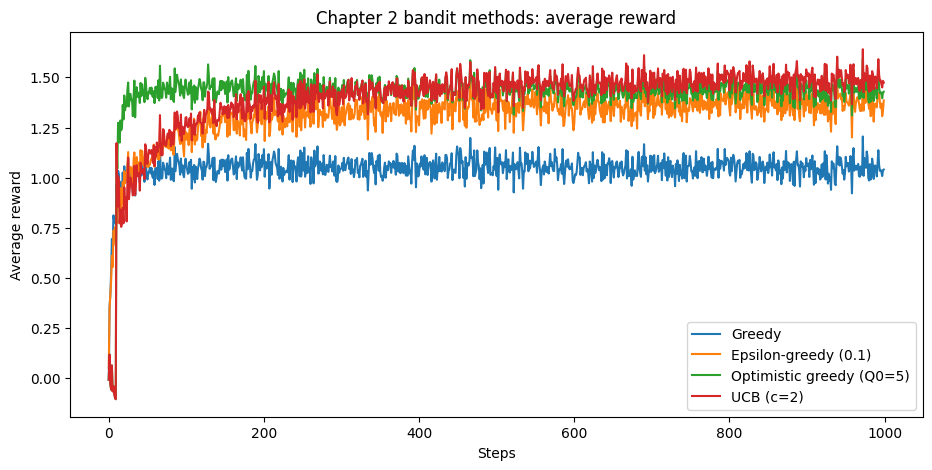

In [14]:
plt.figure(figsize=(11, 5))

for name, result in results.items():
    plt.plot(
        result["avg_reward"],
        label=name
    )

plt.xlabel("Steps")
plt.ylabel("Average reward")
plt.title("Chapter 2 bandit methods: average reward")
plt.legend()
plt.show()


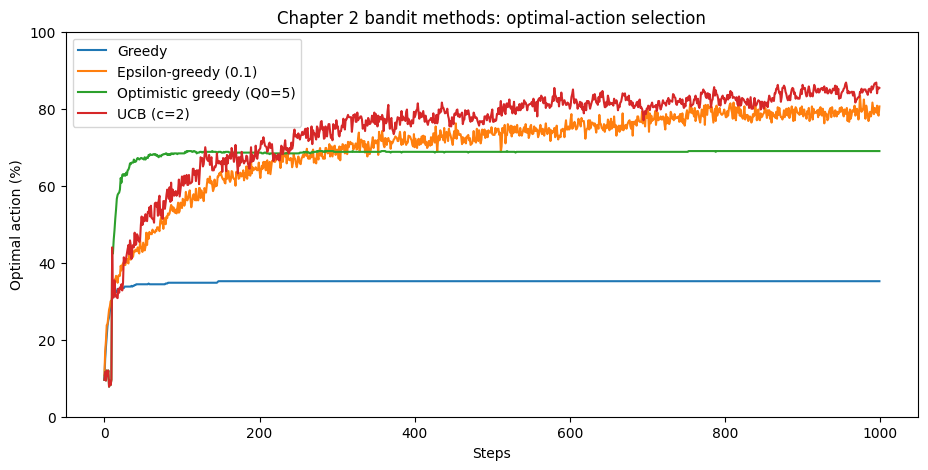

In [15]:
plt.figure(figsize=(11, 5))

for name, result in results.items():
    plt.plot(
        100 * result["optimal_rate"],
        label=name
    )

plt.xlabel("Steps")
plt.ylabel("Optimal action (%)")
plt.title("Chapter 2 bandit methods: optimal-action selection")
plt.ylim(0, 100)
plt.legend()
plt.show()


# 9. What should you expect?

## Greedy

Greedy often improves quickly but can lock onto a suboptimal action because of noisy early rewards.

Its weakness is:

\[
\boxed{\text{No intentional exploration}}
\]

---

## $\epsilon$-greedy

It keeps exploring forever.

That makes it robust against early mistakes, but it also means it deliberately chooses inferior actions some fraction of the time.

Its exploration rule is:

\[
\boxed{\text{Explore randomly}}
\]

---

## Optimistic initial values

Optimism encourages early exploration because untried actions retain artificially high estimates.

Its exploration rule is effectively:

\[
\boxed{\text{Untried actions look unusually attractive}}
\]

But the effect fades after the estimates become realistic.

---

## UCB

UCB gives an exploration bonus to actions that have not been sampled enough.

Its exploration rule is:

\[
\boxed{\text{Explore where uncertainty is large}}
\]

That is generally more directed than random exploration.


# 10. Direct comparison of the ideas

| Method | Exploitation | Exploration | Main weakness |
|---|---|---|---|
| Greedy | Always chooses current best estimate | None | Can get stuck |
| $\epsilon$-greedy | Usually chooses current best | Random action with probability $\epsilon$ | Wastes some exploration |
| Optimistic values | Greedy after initialization | Early optimism pushes untried actions | Exploration fades |
| UCB | Uses estimated value | Adds uncertainty bonus | Requires count-based confidence idea |

A useful mental summary:

\[
\boxed{
\text{Greedy}
=
\text{What looks best?}
}
\]

\[
\boxed{
\epsilon\text{-greedy}
=
\text{What looks best, except when I randomly investigate?}
}
\]

\[
\boxed{
\text{Optimistic initialization}
=
\text{What still looks suspiciously promising because I barely tested it?}
}
\]

\[
\boxed{
\text{UCB}
=
\text{What looks best after accounting for uncertainty?}
}
\]


# 11. Experiment: change $\epsilon$

Let's see how exploration strength affects $\epsilon$-greedy behavior.


In [ ]:
epsilon_values = [0.0, 0.01, 0.05, 0.1, 0.2, 0.5]

epsilon_results = {}

for eps in epsilon_values:
    avg_reward, optimal_rate = evaluate_method(
        method="epsilon_greedy",
        epsilon=eps,
        runs=300,
        steps=1000,
        base_seed=5000
    )

    epsilon_results[eps] = {
        "avg_reward": avg_reward,
        "optimal_rate": optimal_rate
    }


In [ ]:
final_rewards = [
    epsilon_results[eps]["avg_reward"][-100:].mean()
    for eps in epsilon_values
]

plt.figure(figsize=(8, 4))
plt.plot(epsilon_values, final_rewards, marker="o")
plt.xlabel("epsilon")
plt.ylabel("Mean reward over final 100 steps")
plt.title("Effect of epsilon on long-run reward")
plt.show()


There is no universally best fixed $\epsilon$.

The result depends on:

- number of actions,
- reward noise,
- task duration,
- stationarity,
- initialization,
- value-estimation method.

The important point is the tradeoff, not memorizing one magic number.


# 12. Experiment: change the optimistic initial value

Now compare different initial values while keeping the policy greedy.


In [ ]:
initial_values = [0.0, 1.0, 2.5, 5.0, 10.0]

optimistic_results = {}

for q0 in initial_values:
    avg_reward, optimal_rate = evaluate_method(
        method="optimistic",
        initial_value=q0,
        runs=300,
        steps=1000,
        base_seed=7000
    )

    optimistic_results[q0] = {
        "avg_reward": avg_reward,
        "optimal_rate": optimal_rate
    }


In [ ]:
plt.figure(figsize=(10, 5))

for q0 in initial_values:
    plt.plot(
        100 * optimistic_results[q0]["optimal_rate"],
        label=f"Q0={q0}"
    )

plt.xlabel("Steps")
plt.ylabel("Optimal action (%)")
plt.title("Effect of optimistic initialization")
plt.ylim(0, 100)
plt.legend()
plt.show()


A very large optimistic value can force broad early exploration, but excessive optimism can also make learning noisy and slow.

Optimism is therefore not free exploration. It is a design choice with consequences.


# 13. Experiment: change UCB parameter $c$

The parameter $c$ controls the strength of the exploration bonus.

Let's compare several values.


In [ ]:
c_values = [0.1, 0.5, 1.0, 2.0, 4.0]

ucb_results = {}

for c in c_values:
    avg_reward, optimal_rate = evaluate_method(
        method="ucb",
        c=c,
        runs=300,
        steps=1000,
        base_seed=9000
    )

    ucb_results[c] = {
        "avg_reward": avg_reward,
        "optimal_rate": optimal_rate
    }


In [ ]:
plt.figure(figsize=(10, 5))

for c in c_values:
    plt.plot(
        ucb_results[c]["avg_reward"],
        label=f"c={c}"
    )

plt.xlabel("Steps")
plt.ylabel("Average reward")
plt.title("Effect of UCB exploration parameter c")
plt.legend()
plt.show()


Interpretation:

- very small $c$ makes UCB behave more greedily,
- larger $c$ increases exploration,
- excessively large $c$ can overexplore.

Again, the useful lesson is not one magic value of $c$.

The useful lesson is:

\[
c
\quad\text{controls the importance of uncertainty.}
\]


# 14. Exercise 1

Suppose:

\[
Q=[1.0,\;1.4,\;0.9].
\]

Which action does greedy selection choose?


In [ ]:
Q = np.array([1.0, 1.4, 0.9])
rng = np.random.default_rng(1)

print("Selected action:", greedy_action(Q, rng))


# 15. Exercise 2

Suppose:

\[
k=5,\qquad \epsilon=0.2.
\]

What is the probability that $\epsilon$-greedy selects the greedy action?

Use:

\[
1-\epsilon+\frac{\epsilon}{k}.
\]


In [ ]:
epsilon = 0.2
k = 5

p_greedy = 1 - epsilon + epsilon / k

print("Probability =", p_greedy)


# 16. Exercise 3

Suppose two actions have:

\[
Q(A)=1.5,\quad N(A)=100
\]

and

\[
Q(B)=1.3,\quad N(B)=4.
\]

At

\[
t=100,\qquad c=2,
\]

which action does UCB prefer?

Predict before running the next cell.


In [ ]:
Q = np.array([1.5, 1.3])
N = np.array([100, 4])

t = 100
c = 2.0

bonus = c * np.sqrt(np.log(t) / N)
scores = Q + bonus

print("Bonuses:", np.round(bonus, 3))
print("UCB scores:", np.round(scores, 3))
print("Selected action:", np.argmax(scores))


# 17. Exercise 4

Change this configuration:

```python
methods = {
    "Greedy": ...,
    "Epsilon-greedy": ...,
    "Optimistic": ...,
    "UCB": ...
}
```

Try your own values for:

- $\epsilon$
- $Q_0$
- $c$

Then ask:

1. Which method learns the best action fastest?
2. Which method achieves the highest long-run reward?
3. Which method explores most aggressively early?
4. Which method continues exploring indefinitely?


# 18. Final Chapter 2 summary

The central problem is **exploration vs. exploitation**.

## Greedy

\[
A_t=\arg\max_a Q_t(a)
\]

Pure exploitation.

---

## $\epsilon$-greedy

\[
A_t=
\begin{cases}
\text{random action}, & \text{with probability }\epsilon\\
\arg\max_aQ_t(a), & \text{otherwise}
\end{cases}
\]

Simple persistent exploration.

---

## Optimistic initial values

Initialize:

\[
Q_1(a)\gg q_*(a).
\]

A greedy policy then explores because untried actions remain optimistic.

Best thought of as **early exploration induced by initialization**.

---

## UCB

\[
A_t
=
\arg\max_a
\left[
Q_t(a)
+
c\sqrt{\frac{\ln t}{N_t(a)}}
\right].
\]

Exploration is directed toward actions with greater uncertainty.

---

The conceptual progression is:

\[
\boxed{
\text{Greedy}
\rightarrow
\text{Random exploration}
\rightarrow
\text{Optimistic exploration}
\rightarrow
\text{Uncertainty-aware exploration}
}
\]

These are different answers to one question:

> How should an agent collect information while also trying to obtain reward?
